# 03 - SVM, Random Forest & KNN (C)

# 1. Preparation

## 1.1 Imports

In [39]:

import sys
sys.path.append("..")

from src.config import *
from src.data import load_split
from src.cleaning import clean_text
from src.evaluate import evaluate, save_results

import pandas as pd

from src.model import build_pipeline

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import f1_score
from sklearn.model_selection import GridSearchCV



## 1.2 Loading the data

In [40]:

# Load cleaned datasets
train = pd.read_csv(PROCESSED_DIR / "train.csv")
val = pd.read_csv(PROCESSED_DIR / "validation.csv")

# Separate features and labels
X_train = train[TEXT_COL]
y_train = train["label"]

X_val = val[TEXT_COL]
y_val = val["label"]

# Check dimensions
print("Training:", X_train.shape)
print("Validation:", X_val.shape)


Training: (2859,)
Validation: (955,)


# 2. SVM

## 2.1 Baseline: SVM with default settings

Before tuning anything, we train **one simple SVM with its default settings** through the shared pipeline (TF-IDF + model).

We use `LinearSVC`, the SVM version made for large sparse data like TF-IDF text vectors.

---SVM baseline---
              precision    recall  f1-score   support

   non_irony      0.637     0.627     0.632       499
       irony      0.599     0.610     0.604       456

    accuracy                          0.619       955
   macro avg      0.618     0.618     0.618       955
weighted avg      0.619     0.619     0.619       955



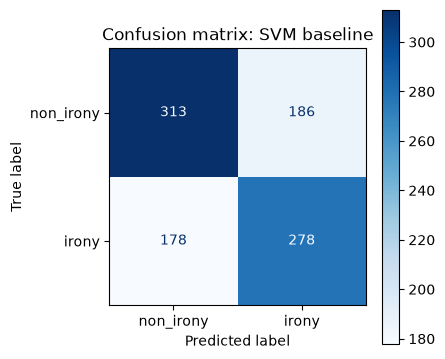

Number of TF-IDF features: 6976


{'model': 'SVM baseline',
 'accuracy': 0.618848167539267,
 'precision': 0.5991379310344828,
 'recall': 0.6096491228070176,
 'f1': 0.6043478260869565,
 'macro_f1': 0.6183355292050944}

In [41]:

# Shared pipeline = TF-IDF vectorizer + a default SVM
baseline = build_pipeline(LinearSVC(random_state=RANDOM_STATE))

# Learn on the training tweets only (the pipeline fits TF-IDF on train too, so no leakage)
baseline.fit(X_train, y_train)

# Predict the validation tweets and score them with the team's evaluate()
y_pred = baseline.predict(X_val)
metrics_base = evaluate("SVM baseline", y_val, y_pred, save_fig=False)

# How many numbers (features) describe each tweet after TF-IDF?
n_features = len(baseline.named_steps["tfidf"].get_feature_names_out())
print("Number of TF-IDF features:", n_features)
metrics_base

## 2.2 Tuning the SVM with GridSearchCV

The SVM has one important setting (a **hyperparameter**): `C`, which controls how strict the model is on the training tweets.
- **small C** → the model accepts some mistakes on train and keeps a smooth, simple boundary (less overfitting)
- **large C** → the model tries hard to classify every training tweet correctly (risk of overfitting)

We test 7 values of `C` with `GridSearchCV`: for each value, it trains and scores the pipeline with **5-fold cross-validation on the training set only**, using **macro-F1**.
The best `C` is then evaluated once on the validation split.

Best parameters: {'clf__C': 0.5}
Best CV macro-F1: 0.6322


,param_clf__C,mean_test_score,std_test_score,rank_test_score
0,0.01,0.5767,0.0228,7
1,0.10,0.6254,0.0186,2
2,0.50,0.6322,0.0172,1
3,1.00,0.6203,0.0171,3
4,5.00,0.6119,0.0163,4
5,10.00,0.6081,0.0195,5
6,100.00,0.6014,0.0175,6


---SVM tuned---
              precision    recall  f1-score   support

   non_irony      0.642     0.615     0.628       499
       irony      0.597     0.625     0.611       456

    accuracy                          0.620       955
   macro avg      0.620     0.620     0.620       955
weighted avg      0.621     0.620     0.620       955



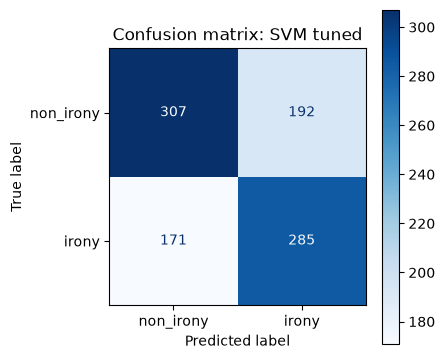

In [42]:

# Same shared pipeline; max_iter is raised so that large values of C can converge
pipe_svm = build_pipeline(LinearSVC(max_iter=10000, random_state=RANDOM_STATE))

# Values of C to try 
param_grid_svm = {"clf__C": [0.01, 0.1, 0.5, 1, 5, 10, 100]}

# 5-fold cross-validation on TRAIN, scored with macro-F1 
grid_svm = GridSearchCV(pipe_svm, param_grid_svm, cv=5, scoring="f1_macro", n_jobs=-1)
grid_svm.fit(X_train, y_train)

print("Best parameters:", grid_svm.best_params_)
print("Best CV macro-F1:", round(grid_svm.best_score_, 4))

# Table of all the tested values
cv_svm = pd.DataFrame(grid_svm.cv_results_)[["param_clf__C", "mean_test_score", "std_test_score", "rank_test_score"]]
display(cv_svm.round(4))

# Evaluate the best SVM on the validation split
y_pred_svm = grid_svm.predict(X_val)
metrics_svm = evaluate("SVM tuned", y_val, y_pred_svm)

## 2.3 Overfitting check


In [43]:

train_f1_svm = f1_score(y_train, grid_svm.predict(X_train), average="macro")
val_f1_svm = metrics_svm["macro_f1"]

print("Train macro-F1     :", round(train_f1_svm, 4))
print("Validation macro-F1:", round(val_f1_svm, 4))
print("Gap                :", round(train_f1_svm - val_f1_svm, 4))

Train macro-F1     : 0.9755
Validation macro-F1: 0.6197
Gap                : 0.3558


# 3. Random Forest

A `Random Forest` is a group of many decision trees. Each tree asks a series of yes/no questions about the tweet (for example "does it contain the word *love*?") and votes ironic or not ironic. The forest takes the `majority vote`.
Each tree sees a random sample of the tweets and a random subset of the words at each split, so the trees make different mistakes and the vote is more reliable than a single tree.

## 3.1 Baseline with default settings

---RF baseline---
              precision    recall  f1-score   support

   non_irony      0.642     0.585     0.612       499
       irony      0.586     0.643     0.613       456

    accuracy                          0.613       955
   macro avg      0.614     0.614     0.613       955
weighted avg      0.615     0.613     0.613       955



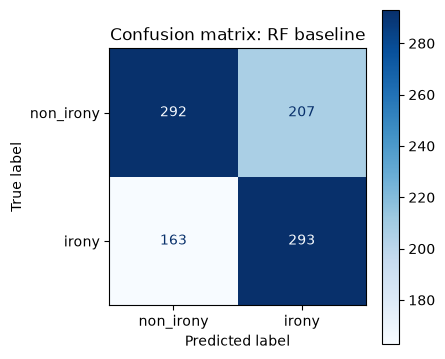

{'model': 'RF baseline',
 'accuracy': 0.612565445026178,
 'precision': 0.586,
 'recall': 0.6425438596491229,
 'f1': 0.6129707112970711,
 'macro_f1': 0.6125650202187662}

In [44]:

# Default Random Forest through the shared pipeline
rf_base = build_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))
rf_base.fit(X_train, y_train)

metrics_rf_base = evaluate("RF baseline", y_val, rf_base.predict(X_val), save_fig=False)
metrics_rf_base

## 3.2 Tuning with GridSearchCV

We tune three hyperparameters (5-fold CV on train, macro-F1):
- `n_estimators`: number of trees in the forest
- `max_depth`: maximum number of questions a tree can ask in a row (`None` = no limit)
- `min_samples_leaf`: minimum number of tweets in a final leaf (larger = simpler trees, less overfitting)


In [45]:
pipe_rf = build_pipeline(RandomForestClassifier(random_state=RANDOM_STATE))

param_grid_rf = {
    "clf__n_estimators": [100, 300],
    "clf__max_depth": [None, 50],
    "clf__min_samples_leaf": [1, 3],
}

grid_rf = GridSearchCV(pipe_rf, param_grid_rf, cv=5, scoring="f1_macro", n_jobs=-1)
grid_rf.fit(X_train, y_train)

print("Best parameters:", grid_rf.best_params_)
print("Best CV macro-F1:", round(grid_rf.best_score_, 4))

Best parameters: {'clf__max_depth': None, 'clf__min_samples_leaf': 3, 'clf__n_estimators': 300}
Best CV macro-F1: 0.6312


## 3.3 All tested combinations

`mean_test_score` is the average macro-F1 over the 5 folds and `std_test_score` is how much the 5 scores vary.
A gap between two rows that is smaller than the std is probably just luck.

In [46]:
cv_rf = pd.DataFrame(grid_rf.cv_results_)[[
    "param_clf__n_estimators", "param_clf__max_depth", "param_clf__min_samples_leaf",
    "mean_test_score", "std_test_score", "rank_test_score"]]

display(cv_rf.sort_values("rank_test_score").round(4))

,param_clf__n_estimators,param_clf__max_depth,param_clf__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
3,300,None,3,0.6312,0.0187,1
7,300,50,3,0.6302,0.0239,2
0,100,None,1,0.6282,0.0241,3
4,100,50,1,0.6279,0.0280,4
5,300,50,1,0.6258,0.0198,5
6,100,50,3,0.6229,0.0224,6
2,100,None,3,0.6222,0.0144,7
1,300,None,1,0.6213,0.0253,8


## 3.4 Evaluation of the best forest on validation

---Random Forest tuned---
              precision    recall  f1-score   support

   non_irony      0.662     0.615     0.638       499
       irony      0.609     0.656     0.631       456

    accuracy                          0.635       955
   macro avg      0.635     0.635     0.635       955
weighted avg      0.636     0.635     0.635       955



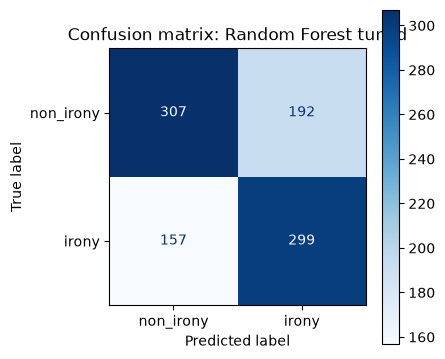

In [47]:
y_pred_rf = grid_rf.predict(X_val)
metrics_rf = evaluate("Random Forest tuned", y_val, y_pred_rf)

## 3.5 Overfitting check


In [48]:
train_f1 = f1_score(y_train, grid_rf.predict(X_train), average="macro")
val_f1 = metrics_rf["macro_f1"]

print("Train macro-F1     :", round(train_f1, 4))
print("Validation macro-F1:", round(val_f1, 4))
print("Gap                :", round(train_f1 - val_f1, 4))

Train macro-F1     : 0.8863
Validation macro-F1: 0.6345
Gap                : 0.2518


# 4. KNN (K-Nearest Neighbors)

KNN does not really "learn" anything. It **stores all the training tweets**, and to classify a new tweet it finds the `k` most similar training tweets (its *neighbors*) and takes the **majority vote** of their labels.
"Similar" means close in the TF-IDF space: two tweets that share many of the same (weighted) words are close.

## 4.1 Baseline with default settings

---KNN baseline---
              precision    recall  f1-score   support

   non_irony      0.703     0.194     0.305       499
       irony      0.508     0.910     0.652       456

    accuracy                          0.536       955
   macro avg      0.605     0.552     0.478       955
weighted avg      0.610     0.536     0.470       955



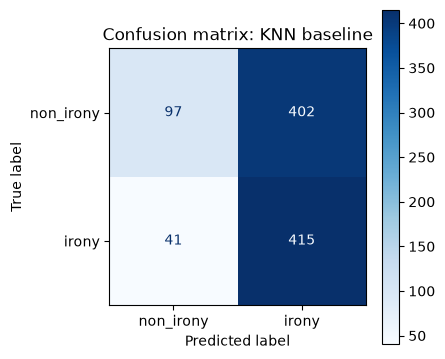

{'model': 'KNN baseline',
 'accuracy': 0.5361256544502618,
 'precision': 0.5079559363525091,
 'recall': 0.9100877192982456,
 'f1': 0.6520031421838177,
 'macro_f1': 0.47827786622534685}

In [49]:

# Default KNN (k = 5) through the shared pipeline
knn_base = build_pipeline(KNeighborsClassifier())
knn_base.fit(X_train, y_train)

metrics_knn_base = evaluate("KNN baseline", y_val, knn_base.predict(X_val), save_fig=False)
metrics_knn_base

## 4.2 Tuning with GridSearchCV

We tune two hyperparameters (5-fold CV on train, macro-F1):
- `n_neighbors` (k): how many neighbors vote. Small k = very sensitive to single tweets (overfitting), large k = smoother but less precise. We use odd values to avoid ties between the two classes.
- `weights`: `uniform` = every neighbor counts the same, `distance` = closer neighbors count more.


In [50]:
pipe_knn = build_pipeline(KNeighborsClassifier())

param_grid_knn = {
    "clf__n_neighbors": [3, 5, 11, 21, 41, 81, 91, 101],
    "clf__weights": ["uniform", "distance"],
}

grid_knn = GridSearchCV(pipe_knn, param_grid_knn, cv=5, scoring="f1_macro", n_jobs=-1)
grid_knn.fit(X_train, y_train)

print("Best parameters:", grid_knn.best_params_)
print("Best CV macro-F1:", round(grid_knn.best_score_, 4))

Best parameters: {'clf__n_neighbors': 81, 'clf__weights': 'distance'}
Best CV macro-F1: 0.6032


## 4.3 All tested combinations

In [51]:
cv_knn = pd.DataFrame(grid_knn.cv_results_)[[
    "param_clf__n_neighbors", "param_clf__weights",
    "mean_test_score", "std_test_score", "rank_test_score"]]

display(cv_knn.sort_values("rank_test_score").round(4))

,param_clf__n_neighbors,param_clf__weights,mean_test_score,std_test_score,rank_test_score
11,81,distance,0.6032,0.0218,1
10,81,uniform,0.6004,0.0214,2
13,91,distance,0.6003,0.0226,3
12,91,uniform,0.6000,0.0231,4
8,41,uniform,0.5985,0.0190,5
9,41,distance,0.5985,0.0180,6
15,101,distance,0.5960,0.0218,7
14,101,uniform,0.5939,0.0224,8
7,21,distance,0.5901,0.0277,9
6,21,uniform,0.5894,0.0272,10


## 4.4 Evaluation of the best KNN on validation

---KNN tuned---
              precision    recall  f1-score   support

   non_irony      0.624     0.571     0.596       499
       irony      0.570     0.623     0.595       456

    accuracy                          0.596       955
   macro avg      0.597     0.597     0.596       955
weighted avg      0.598     0.596     0.596       955



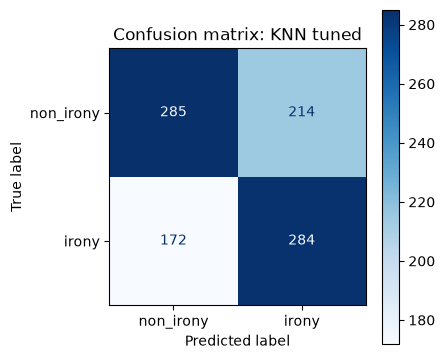

In [52]:
y_pred_knn = grid_knn.predict(X_val)
metrics_knn = evaluate("KNN tuned", y_val, y_pred_knn)

## 4.5 Overfitting check


In [53]:
train_f1_knn = f1_score(y_train, grid_knn.predict(X_train), average="macro")
val_f1_knn = metrics_knn["macro_f1"]

print("Train macro-F1     :", round(train_f1_knn, 4))
print("Validation macro-F1:", round(val_f1_knn, 4))
print("Gap                :", round(train_f1_knn - val_f1_knn, 4))

Train macro-F1     : 0.9997
Validation macro-F1: 0.5958
Gap                : 0.4038
